# Gene Set Enrichment Analysis

Andrew E. Davidson   
aedavids@ucsc.edu  
Date: 2026-05-26.  
Copyright (c) 2020-2027, Regents of the University of California All rights reserved.  
https://polyformproject.org/licenses/noncommercial/1.0.0  

for each diagnosis, run gseapy preRank() on extra vs intra deseq results

In [1]:
defaultNotebookName="gsea"

from cliUtilities import configLogging
import logging

rootLogger = configLogging(logLevel="INFO")
# rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-11-22 10:38:00,510 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-11-22 10:38:00,510 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks]
2026-11-22 10:38:00,511 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/graceM/src/python/cliUtilities.py]
2026-11-22 10:38:00,512 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/graceM/src/jupyterNotebooks]


In [2]:
import gseapy as gp
from IPython.display import display
import matplotlib.pyplot as plt
import os
import pandas as pd
from pathlib import Path

#
# local imports
#
from notebookUtils import appendToPYTHONPATH, getNotebookName
 
ORIG_PYTHONPATH = os.environ['PYTHONPATH']
extraRNA_PythonPath2 = '/private/home/aedavids/extraCellularRNA/src'

appendToPYTHONPATH([extraRNA_PythonPath2, ]) 

from archive.archiveUtilities import saveFigure
from explainability.gseaUtilities import addHUGOIds, cleanUpDups, createGSEA_RepeatDataSet
from explainability.gseaUtilities import createEnsembleToHUGOMap, createGSEAConfig, createPreRankGeneSetsArgument
from explainability.gseaUtilities import CustomLibraryParameters # , downloadMsigdbGmt
from explainability.gseaUtilities import exploreGeneSetDict, GSEAConfig, runPrerank, saveGSEAConfig
from utilities import smartDisplay

2026-11-22 10:38:00,705 INFO utils.py _init_num_threads() line:148] [Note: detected 160 virtual cores but NumExpr set to maximum of 64, check "NUMEXPR_MAX_THREADS" environment variable.]
2026-11-22 10:38:00,706 INFO utils.py _init_num_threads() line:151] [Note: NumExpr detected 160 cores but "NUMEXPR_MAX_THREADS" not set, so enforcing safe limit of 16.]
2026-11-22 10:38:00,707 INFO utils.py _init_num_threads() line:164] [NumExpr defaulting to 16 threads.]
2026-11-22 10:38:02,502 WARNING notebookUtils.py appendToPYTHONPATH() line:40] [Updated PYTHONPATH: /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks:/private/home/aedavids/extraCellularRNA/src]


In [3]:
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')
notebookOutDir = f'{notebookDir}/{notebookName}.out'

imgOutDir = f'{notebookOutDir}/img'
os.makedirs(imgOutDir, exist_ok=True)

imgPanelOutDir = f'{imgOutDir}/panel'
os.makedirs(imgPanelOutDir, exist_ok=True)

dataOutDir = f'/scratch/aedavids/fagazi/{notebookName}.out'
os.makedirs(dataOutDir, exist_ok=True)

cacheDir = f'{dataOutDir}/cache'
msigdbCacheDir = f'{cacheDir}/msigdb'
os.makedirs(msigdbCacheDir, exist_ok=True)

tmpDir = f'{dataOutDir}/tmp'
os.makedirs(tmpDir, exist_ok=True)

theMeaningOfLife = 42

2026-11-22 10:38:02,791 INFO notebookUtils.py getNotebookName() line:83] [BEGIN]
2026-11-22 10:38:02,793 INFO notebookUtils.py getNotebookName() line:111] [END]


notebookName: gsea
notebookDir: /private/home/aedavids/graceM/src/jupyterNotebooks


In [4]:
# analyzeIntraExtra.ipnb filterDESeqResultsByExpressionRate()
#   - loads extra vs intra results
#   - design: ~gender + extraIntra 
#   /private/groups/kimlab/data/elifeGTExTCGA/cromwell.output/Esophagus/intra_vs_all.results
#   select features that are expressed in extra
resultsDir = "/scratch/aedavids/fagazi/analyzeIntraExtra.out"
resultsFiles = !ls $resultsDir/*/expressed*
resultsFiles[0:6]

['/scratch/aedavids/fagazi/analyzeIntraExtra.out/Colorectal/expressedInElife.results',
 '/scratch/aedavids/fagazi/analyzeIntraExtra.out/Colorectal/expressedInGTEx.results',
 '/scratch/aedavids/fagazi/analyzeIntraExtra.out/Colorectal/expressedInTCGA.results',
 '/scratch/aedavids/fagazi/analyzeIntraExtra.out/Esophagus/expressedInElife.results',
 '/scratch/aedavids/fagazi/analyzeIntraExtra.out/Esophagus/expressedInGTEx.results',
 '/scratch/aedavids/fagazi/analyzeIntraExtra.out/Esophagus/expressedInTCGA.results']

In [5]:
customGeneSetLibraries = [
    CustomLibraryParameters('clade', 
                           "/private/groups/kimlab/genomes.annotations/genomes.annotations/gencode.39/named_ucsc.rmsk.insert.info.txt"
                           ),
    CustomLibraryParameters('family', 
                           "/private/groups/kimlab/genomes.annotations/genomes.annotations/gencode.39/named_ucsc.rmsk.insert.info.txt"
                           )
]

colorectalHallmarkConfig_DEBUG = createGSEAConfig(
    "Colorectal Cancer",
    geneSetLibraries=['MSigDB_Hallmark_2020',
                      'GO_Biological_Process_2026',
                      'KEGG_2026',
                      ],
    customGeneSetLibraries=customGeneSetLibraries,
    )


In [6]:

geneSetLibraryFileNames = [ 
                            'c6.all.v2026.1.Hs.symbols.gmt', # MSigDB_Oncogenic_Signatures
                            'Tabula_Sapiens',
                            'h.all.v2026.1.Hs.symbols.gmt', # 'MSigDB_Hallmark_2020', # 
                            'c5.go.bp.v2026.1.Hs.symbols.gmt', #'GO_Biological_Process_2026', #
                            'KEGG_2026', # c2.cp.kegg.v2026.1.Hs.symbols.gmt
                            'GTEx_Tissues_V8_2023',
                            'ARCHS4_Tissues',
                      ]

geneSetCollections = [
    'MSigDB_Oncogenic_Signatures', # C6
    'Tabula_Sapiens', 
    'MSigDB_Hallmark_2020',
    'KEGG_2026',
    'GTEx_Tissues_V8_2023',
    'ARCHS4_Tissues',
]

geneSetLibraryPaths = []
for gs in geneSetCollections :
    t = (gs, gs)
    geneSetLibraryPaths.append(t)

In [7]:
geneSetLibraryPaths

[('MSigDB_Oncogenic_Signatures', 'MSigDB_Oncogenic_Signatures'),
 ('Tabula_Sapiens', 'Tabula_Sapiens'),
 ('MSigDB_Hallmark_2020', 'MSigDB_Hallmark_2020'),
 ('KEGG_2026', 'KEGG_2026'),
 ('GTEx_Tissues_V8_2023', 'GTEx_Tissues_V8_2023'),
 ('ARCHS4_Tissues', 'ARCHS4_Tissues')]

In [8]:
colorectalConfig = createGSEAConfig(
    "Colorectal Cancer",
    geneSetLibraries=geneSetLibraryPaths,
    customGeneSetLibraries=customGeneSetLibraries,
    )

esophagusConfig = createGSEAConfig(
    "Esophagus Cancer",
    geneSetLibraries=geneSetLibraryPaths,
    customGeneSetLibraries=customGeneSetLibraries,
    )

healthyConfig= createGSEAConfig(
    "Healthy donor",
    geneSetLibraries=geneSetLibraryPaths,
    customGeneSetLibraries=customGeneSetLibraries,
    )

lungConfig = createGSEAConfig(
    "Lung Cancer",
    geneSetLibraries=geneSetLibraryPaths,
    customGeneSetLibraries=customGeneSetLibraries,
    )

liverConfig = createGSEAConfig(
    "Liver Cancer",
    geneSetLibraries=geneSetLibraryPaths,
    customGeneSetLibraries=customGeneSetLibraries,
    )

stomachConfig = createGSEAConfig(
    "Stomach Cancer",
    geneSetLibraries=geneSetLibraryPaths,
    customGeneSetLibraries=customGeneSetLibraries,
    )

# GSEA_CONFIG = aedwip colorectalHallmarkConfig_DEBUG
GSEA_CONFIG = colorectalConfig
# GSEA_CONFIG = esophagusConfig
# GSEA_CONFIG = healthyConfig
# GSEA_CONFIG = lungConfig
# GSEA_CONFIG = liverConfig
# GSEA_CONFIG = stomachConfig


In [9]:
# make sure we save current configuration to ensure "pedigree" and "repeatability"
diagnosisDir = f'{notebookOutDir}/{GSEA_CONFIG.diagnosis.value}'
os.makedirs(diagnosisDir, exist_ok=True)
configPath = f'{diagnosisDir}/gseaConfig.json'
saveGSEAConfig(GSEA_CONFIG, configPath)

saved : /private/home/aedavids/graceM/src/jupyterNotebooks/gsea.out/Colorectal/gseaConfig.json


# <span style="color:red;background-color:yellow;">ucsc rmask insert info</span>
create dictionay we can use with preRank(gene_sets). 
keys = clade and values are list of insert features

In [10]:

geneSetCladeDict, ucscRmskDF = createGSEA_RepeatDataSet('clade')
print(f'ucscRmskDF.shape : {ucscRmskDF.shape}')
display(ucscRmskDF.head())

cladeLociList = exploreGeneSetDict(geneSetCladeDict)
print(f'len(cladeLociList) : {len(cladeLociList)}')
print(cladeLociList)

geneSetFamilyDict, _ = createGSEA_RepeatDataSet('family')
       
familyLociList = exploreGeneSetDict(geneSetFamilyDict)
print(f'len(familyLociList) : {len(familyLociList)}')
# print(f'first 3 ')
print(familyLociList)

ucscRmskDF.shape : (15625, 3)


,clade,family,insert
0,Simple_repeat,Simple_repeat,(TAACCC)n
1,Satellite,telo,TAR1
2,LINE,L1,L1MC5a
3,DNA,hAT-Charlie,MER5B
4,SINE,MIR,MIR3


len(cladeLociList) : 17
[('DNA', 322), ('DNA?', 30), ('LINE', 183), ('LTR', 589), ('LTR?', 7), ('Low_complexity', 4), ('RC', 3), ('Retroposon', 6), ('SINE', 63), ('SINE?', 2), ('Satellite', 25), ('Simple_repeat', 14228), ('Unknown', 76), ('rRNA', 3), ('scRNA', 5), ('snRNA', 13), ('tRNA', 63)]
len(familyLociList) : 51
[('Alu', 54), ('CR1', 25), ('Crypton', 3), ('DNA', 27), ('DNA?', 28), ('ERV1', 299), ('ERV1?', 3), ('ERVK', 42), ('ERVL', 121), ('ERVL-MaLR', 86), ('ERVL?', 5), ('Gypsy', 18), ('Gypsy?', 6), ('Helitron', 3), ('L1', 132), ('L2', 16), ('LTR', 9), ('LTR?', 7), ('Low_complexity', 4), ('MIR', 5), ('MULE-MuDR', 6), ('MULE-MuDR?', 2), ('Merlin', 3), ('PIF-Harbinger', 3), ('PiggyBac', 5), ('RTE-BovB', 2), ('RTE-X', 4), ('SVA', 6), ('Satellite', 14), ('Simple_repeat', 14228), ('TcMar-Mariner', 6), ('TcMar-Tc1', 3), ('TcMar-Tc2', 8), ('TcMar-Tigger', 80), ('TcMar?', 3), ('Unknown', 76), ('acro', 2), ('centr', 6), ('hAT', 8), ('hAT-Ac', 4), ('hAT-Blackjack', 9), ('hAT-Charlie', 83), 

## <span style="color:red;background-color:yellow;">select the GSEA gene set libraries and configure the analysis parameters</span>
ref: runPrerank()

In [11]:
print(f'GSEA_CONFIG.diagnosis : {GSEA_CONFIG.diagnosis}')
resultsDF = pd.read_csv(GSEA_CONFIG.resultsFilePath, )
resultsDF.dropna(inplace=True)
print(f'resultsDF.shape : {resultsDF.shape}')
resultsDF.head()

GSEA_CONFIG.diagnosis : Diagnosis.COLORECTAL
resultsDF.shape : (10866, 7)


/data/tmp/ipykernel_3207724/3500162124.py:3: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  resultsDF.dropna(inplace=True)


,name,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
5,(AAGG)n,170.455030,8.122555,0.464286,17.494726,1.571677e-68,7.298374e-68
10,(AGA)n,138.507160,8.197866,0.447156,18.333346,4.484539e-75,2.255311e-74
16,(AGCCAAGCC)n,12618.692067,13.915625,0.393800,35.336788,1.599871e-273,1.039776e-271
18,(AGG)n,195.826229,10.168938,0.503500,20.196492,1.051042e-90,6.286484e-90
21,(AGGGTT)n,20.599107,8.282982,0.594961,13.921891,4.663978e-44,1.617623e-43


# <span style="color:red;background-color:yellow;">map Ensemble ids to HUGO</span>
Most of the gene set databases use HUGO id

In [12]:
v39GeneMapPath= f'{dataOutDir}/v39GeneMap.csv'
v39GeneMapDF = createEnsembleToHUGOMap(mapFilePath=v39GeneMapPath)

print(f'v39GeneMapDF.shape : {v39GeneMapDF.shape}')
smartDisplay(v39GeneMapDF.head(n=2))
print()
smartDisplay(v39GeneMapDF.tail(n=2))

2026-11-22 10:38:02,952 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/gsea.out/v39GeneMap.pandas.h5]


v39GeneMapDF.shape : (77116, 7)


,HUGO,ENSG,base,version,originalENSG,bioType,isENSG
39389,DDX11L1,ENSG00000223972.5,ENSG00000223972,5,ENSG00000223972.5,"[processed_transcript, transcribed_unprocessed_pseudogene]",True
41633,WASH7P,ENSG00000227232.5,ENSG00000227232,5,ENSG00000227232.5,[unprocessed_pseudogene],True


,HUGO,ENSG,base,version,originalENSG,bioType,isENSG
13383,(TTCGAGTCCA)n,(TTCGAGTCCA)n,(TTCGAGTCCA)n,NaN,(TTCGAGTCCA)n,[repeatMask],False
12794,(TGTGTGGTG)n,(TGTGTGGTG)n,(TGTGTGGTG)n,NaN,(TGTGTGGTG)n,[repeatMask],False


In [13]:
hugoResultsDF = addHUGOIds( resultsDF, v39GeneMapDF, leftOnColName="name")
print(f'hugoResultsDF.shape.  : {hugoResultsDF.shape}')
hugoResultsDF.head() 

mergedResultsDF.shape :(77116, 10)
gseaInputDF.shape       : (10866, 7)
hugoResultsDF.shape.  : (10866, 9)


,name,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,originalENSG,HUGO
529,(AAGG)n,170.455030,8.122555,0.464286,17.494726,1.571677e-68,7.298374e-68,(AAGG)n,(AAGG)n
1703,(AGA)n,138.507160,8.197866,0.447156,18.333346,4.484539e-75,2.255311e-74,(AGA)n,(AGA)n
2051,(AGCCAAGCC)n,12618.692067,13.915625,0.393800,35.336788,1.599871e-273,1.039776e-271,(AGCCAAGCC)n,(AGCCAAGCC)n
2156,(AGG)n,195.826229,10.168938,0.503500,20.196492,1.051042e-90,6.286484e-90,(AGG)n,(AGG)n
2328,(AGGGTT)n,20.599107,8.282982,0.594961,13.921891,4.663978e-44,1.617623e-43,(AGGGTT)n,(AGGGTT)n


In [14]:
print(f'hugoResultsDF.shape[0] : {hugoResultsDF.shape[0]} resultsDF.shape[0] : {resultsDF.shape[0]}')

emsg0 = "ERROR geneId to HUGO mapping failed. hugoResultsDF.shape[0]"
emsg =  f'{emsg0} : {hugoResultsDF.shape[0]} != resultsDF.shape[0] : {resultsDF.shape[0]}'
assert hugoResultsDF.shape[0] == resultsDF.shape[0], emsg

# check to make sure the ids are unique
# areGeneIdsUnique = not sum( hugoResultsDF.loc[:, 'geneId'].duplicated() ) 
areGeneIdsUnique = not sum( hugoResultsDF.loc[:, 'name'].duplicated() ) 
geneIdEmsg = "Error : 'geneId' are not unique "
assert areGeneIdsUnique == True, geneIdEmsg

areHugoIdsUnique = not sum( hugoResultsDF.loc[:, 'HUGO'].duplicated() ) 
# geneHugoEmsg = "Error : 'HUGO' are not unique"
# assert areHugoIdsUnique == True, geneHugoEmsg

if not areHugoIdsUnique:
    hugoResultsDF = cleanUpDups(hugoResultsDF, rankCol=GSEA_CONFIG.rankCol)

smartDisplay(hugoResultsDF.head())

2026-11-22 10:38:03,264 WARNING gseaUtilities.py cleanUpDups() line:258] [HUGO NAMES are not uniq]
2026-11-22 10:38:03,269 WARNING gseaUtilities.py cleanUpDups() line:270] [keeping index: 
Index([20101], dtype='int64')]


hugoResultsDF.shape[0] : 10866 resultsDF.shape[0] : 10866
                     name    baseMean  log2FoldChange     lfcSE      stat  \
20101  ENSG00000125863.20  959.104021       -1.058893  0.155295 -6.818595   
72260   ENSG00000285508.1  129.022007       -0.686825  0.288238 -2.382837   

             pvalue          padj        originalENSG  HUGO  
20101  9.193490e-12  1.909134e-11  ENSG00000125863.20  MKKS  
72260  1.717981e-02  2.592886e-02   ENSG00000285508.1  MKKS  


,name,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,originalENSG,HUGO
529,(AAGG)n,170.455030,8.122555,0.464286,17.494726,1.571677e-68,7.298374e-68,(AAGG)n,(AAGG)n
1703,(AGA)n,138.507160,8.197866,0.447156,18.333346,4.484539e-75,2.255311e-74,(AGA)n,(AGA)n
2051,(AGCCAAGCC)n,12618.692067,13.915625,0.393800,35.336788,1.599871e-273,1.039776e-271,(AGCCAAGCC)n,(AGCCAAGCC)n
2156,(AGG)n,195.826229,10.168938,0.503500,20.196492,1.051042e-90,6.286484e-90,(AGG)n,(AGG)n
2328,(AGGGTT)n,20.599107,8.282982,0.594961,13.921891,4.663978e-44,1.617623e-43,(AGGGTT)n,(AGGGTT)n


# <span style="color:red;background-color:yellow;">run GSEA prerank()</span>

In [15]:
# rank the results
hugoResultsDF['rank'] = hugoResultsDF[GSEA_CONFIG.rankCol]
hugoResultsDF = hugoResultsDF.sort_values(by='rank', ascending=False).reset_index()

print(f'notice that stat and LFC are positively correlated')
smartDisplay(hugoResultsDF.loc[:, ['log2FoldChange', GSEA_CONFIG.rankCol, 'rank']].head())

print()
smartDisplay(hugoResultsDF.loc[:, ['log2FoldChange', GSEA_CONFIG.rankCol, 'rank']].tail())

notice that stat and LFC are positively correlated


,log2FoldChange,stat,rank
0,13.995508,89.901765,89.901765
1,10.600169,71.663332,71.663332
2,11.489465,64.137458,64.137458
3,9.679760,63.773823,63.773823
4,9.136069,62.062815,62.062815


,log2FoldChange,stat,rank
10860,-6.995464,-48.607979,-48.607979
10861,-5.902631,-49.161243,-49.161243
10862,-9.898960,-49.854282,-49.854282
10863,-5.922712,-54.251789,-54.251789
10864,-6.351060,-70.791706,-70.791706


In [16]:
rankDF = hugoResultsDF.loc[:, ['HUGO', 'rank']]
print(f'rankDF.shape : {rankDF.shape}')
rankDF

rankDF.shape : (10865, 2)


,HUGO,rank
0,TUBB1,89.901765
1,NRGN,71.663332
2,ENSG00000236304,64.137458
3,MAP3K7CL,63.773823
4,GRAP2,62.062815
...,...,...
10860,LAPTM4A,-48.607979
10861,PDIA6,-49.161243
10862,KRT8,-49.854282
10863,IARS2,-54.251789


In [17]:
selectGeneIdMappingsSeries = rankDF.loc[:, 'HUGO'].str.startswith("ENSG")
print(f'number of failed ensembl to HUGO mappings : {sum(selectGeneIdMappingsSeries)} preRank will skip these')
# smartDisplay(rankDF.loc[selectGeneIdMappingsSeries, :])

# assert sum(selectGeneIdMappingsSeries) == 0, "preRank collection tyically use HUGO, these "

number of failed ensembl to HUGO mappings : 464 preRank will skip these


In [18]:
%%time
print(f'GSEA_CONFIG.diagnosis : {GSEA_CONFIG.diagnosis}')

geneSetDatabase = createPreRankGeneSetsArgument(GSEA_CONFIG)

significantTermsDF, preRankResultsDict = runPrerank(
        geneSetDatabase=geneSetDatabase,
        gseaConfig=GSEA_CONFIG,
        rankDF=rankDF,
        fdrThreshold=GSEA_CONFIG.fdrThreshold,
        nesThreshold=GSEA_CONFIG.nesThreshold,
)

significantTermsPath = f'{diagnosisDir}/significantTerms.csv'
significantTermsDF.to_csv(significantTermsPath, index=None)
print(f'saved : {significantTermsPath}')

print(f'\n\n*******\nsignificantTermsDF.shape : {significantTermsDF.shape}')
print(f'head()')
smartDisplay(significantTermsDF.head())
print(f'\ntail')
smartDisplay(significantTermsDF.tail())

GSEA_CONFIG.diagnosis : Diagnosis.COLORECTAL

Diagnosis.COLORECTAL MSigDB_Oncogenic_Signatures fdrThreshold : 0.05 nesThreshold : 1.5
select <= fdrThreshold :fdrPlotDF.shape : (17, 5)
select abs(NES) >= nesThreshold nesPlotDF.shape : (17, 5)

Diagnosis.COLORECTAL Tabula_Sapiens fdrThreshold : 0.05 nesThreshold : 1.5
select <= fdrThreshold :fdrPlotDF.shape : (133, 5)
select abs(NES) >= nesThreshold nesPlotDF.shape : (93, 5)

Diagnosis.COLORECTAL MSigDB_Hallmark_2020 fdrThreshold : 0.05 nesThreshold : 1.5
select <= fdrThreshold :fdrPlotDF.shape : (21, 5)
select abs(NES) >= nesThreshold nesPlotDF.shape : (19, 5)

Diagnosis.COLORECTAL KEGG_2026 fdrThreshold : 0.05 nesThreshold : 1.5
select <= fdrThreshold :fdrPlotDF.shape : (69, 5)
select abs(NES) >= nesThreshold nesPlotDF.shape : (69, 5)

Diagnosis.COLORECTAL GTEx_Tissues_V8_2023 fdrThreshold : 0.05 nesThreshold : 1.5
select <= fdrThreshold :fdrPlotDF.shape : (28, 5)
select abs(NES) >= nesThreshold nesPlotDF.shape : (28, 5)

Diagnosis.COL

,Term,ES,NES,FDR q-val,Lead_genes,diagnosis,geneSetDB
0,KRAS.AMP.LUNG UP.V1 UP,0.433460,2.124207,0.007145,GATA1;TUBA8;F13A1;EGF;FCER1G;DYNC1I1;SDCCAG8;ST3GAL6;OSBP2;FAM30A;CA5A;EFCAB6;RAB30,Diagnosis.COLORECTAL,MSigDB_Oncogenic_Signatures
1,RPS14 DN.V1 DN,-0.397579,-1.578924,0.042959,AGAP1;TBRG4;ECT2;CDC20;CAD;CNN3;MIPEP;BYSL;ERCC2;MRPS2;LGR4;MRPL12;ENG;PRC1;NUP155;TLN2;SLC43A1;GEMIN4;ORC1;GATC;GUF1;EIF2B3;EXO1;ID1;ISOC2;IPO4;MYBL2;KIF23;IL15RA;SHMT1;MYLIP;CDC6;TGM2;NCAPH;PES1;AGFG2;CDR2;CCNB2;RRS1;SRD5A3;RPS28;MCM5;SRM;POLD1;CYBRD1;GCDH;SLC6A8;KLHL7;DNAJA4;DOCK9;PCSK7;ARHGAP11A;KANK2;DEPDC1;BAG2;ALAD;FBXO5,Diagnosis.COLORECTAL,MSigDB_Oncogenic_Signatures
2,PDGF ERK DN.V1 DN,-0.393677,-1.595348,0.036279,SLC3A2;EFNB2;GIPC1;TGIF1;BCL9;SUOX;SPRY2;PISD;MYC;SLC25A44;PPP1R10;NCAPH2;DHX34;ZFP36L2;RHOB;MAPK3;FAM102A;DTX2;JUNB;PRCC;RNF139;CCNF;FBXL18;JUN;SMAD7;TRIB1;IL2RG;MAD2L1BP;DNAJB9;ERF;MAFF;E2F6;MBD3;CDKN1B;DYRK2;MNT;DNAJB1;BRPF1;MGAT1;PDE4A;TBCC;NOP16;CDK2AP2;KLF10;PPP2R5B;POLG2;CKS2;PITPNM1;TFIP11;DIP2A;BTG1;BCL10;FBXL14;IRAK1BP1;ZNF202;MON1B;DUSP6;DUSP1;FRAT2;BCL7B;TMEM11;PHLPP1;EGR1;FADD;NFKBIA;KDM2A;CEBPB;SULT1A1;ANKRD40;ARF6;NFIL3,Diagnosis.COLORECTAL,MSigDB_Oncogenic_Signatures
3,MTOR UP.N4.V1 UP,-0.387046,-1.610273,0.031502,PTPRK;LPCAT4;SLC3A2;IDH1;PLS1;SPRED2;SLC7A5;ASS1;TBRG4;PCK2;HERPUD1;RABEPK;ACACA;BHLHE40;SLC1A5;COASY;MIPEP;CEBPG;LIMA1;LDLR;MAST2;CNIH4;STX4;SAR1B;NUP155;NANS;SLC43A1;CHUK;DHCR7;RRP9;E2F5;PTS;RRP12;PSPH;CDK16;EIF2B3;MGAT4A;VPS33B;RPAP1;ISOC2;CCDC86;GOT1;PDXK;RRP15;ASCC1;SDF2L1;LGMN;IDH3A;EBNA1BP2;EIF4EBP1;OPN3;E2F6;TRAF3IP2;GFPT1;UGCG;MRPL39;GLRX2;ATF3;DDIT3;ELOVL6;RBM28;SLC7A11;SLC39A4;ETNK1;NQO2;KLHL7;GTF2E2;SEC24D;PJA1;COQ2,Diagnosis.COLORECTAL,MSigDB_Oncogenic_Signatures
4,ESC V6.5 UP EARLY.V1 DN,-0.407029,-1.616039,0.030916,KRT8;KRT18;SLC39A1;EMP1;COL4A1;GYS1;PARVA;B4GALT7;S100A6;TAGLN;MAPK13;SLC41A3;ANXA2;BHLHE40;TINAGL1;COL4A2;IGFBP7;ESRRA;FBXO28;CIZ1;TM4SF1;CDC42EP1;MYO7B;JUNB;SOCS3;PRCC;SERPINF1;ZFP36L1;DSP;TIMP2;BCL3;ANXA5;CMTM7;WSB1;ZADH2;ALCAM;YES1,Diagnosis.COLORECTAL,MSigDB_Oncogenic_Signatures



tail


,Term,ES,NES,FDR q-val,Lead_genes,diagnosis,geneSetDB
226,SPERM,0.359316,2.658639,0.000000,ITGA2B;ENKUR;HEMGN;CCDC7;CFAP161;MORC1;EFCAB13;APLF;GP6;PKHD1L1;ANO2;LOXHD1;RGS6;ARMC3;MFAP3L;FAM81B;TUBA8;SLC8A3;ACRBP;FRMD3;ACCSL;HNRNPRP1;IQUB;CCDC180;DRC7;FBXL13;ADAMTS6;BMS1P7;ST3GAL3;CCDC91;CEP128;TEX14;SPATA1;DNAH14;CCDC62;ANKRD36BP2;ZFP91-CNTF;PCP2;NBEAP1;ASS1P1;NUP210L;CMTM2;DPY19L1P1;WDR49;FUNDC2P2;ERICH6;GCOM1;ARHGAP19-SLIT1;CFAP45;ANKRD20A11P;CPNE5;FAM187B2P;PRR7;GKAP1;DPY19L1P2;CA2;CCDC173;CDKL4;GRHL1;OSBP2;ANKRD31;TSNAX-DISC1;CAPN11;ROPN1L;ZBBX;STPG2;TMED10P2;ZMYND12;TXNDC2;PHOSPHO1;NLGN1;DNAH12;SH3GL3;CATSPER1;TNFRSF13B;CPNE4;SLC9C1;HABP4;CAMP;LRRC63;DPY19L2P1;RPH3A;GOLGA6L17P;EFCAB6;FCN1;TP53TG3D;BEST3;RASGRF2;TMC1;RYR2;MYO18B;PHF7;C2CD6;TDRD9,Diagnosis.COLORECTAL,ARCHS4_Tissues
227,DENTATE GRANULE CELL,0.308108,2.128046,0.000000,NRGN;ENKUR;SPX;DNM3;CFAP161;MMD;MORC1;PTP4A2P2;SNCA;P2RY12;ABLIM3;RGS6;GNAZ;MFAP3L;FAM81B;RAB27B;TUBA8;SLC8A3;SH3BGRL2;SSX2IP;ERC2;MCTP1;BBOF1;EHD3;ZFPM2;KHDRBS2;DOK6;ANKRD33B;TDRP;MAP1A;ARHGAP6;ZBTB20;CLEC2L;OR2L13;RAB6B;KCNA3;DGKG;HBQ1;NDST3;ANKRD18DP;VN1R110P;HFM1;NBEAP1;CETN4P;TTLL7;DYNC1I1;PRKACB;DMTN;PDE6H;PKIA;WASF3;LCA5;WDR49;FXYD7;ATL1;ARHGAP19-SLIT1;SLC24A3;CCDC173;BUD13P1;CDKL4;ANKRD31;ROPN1L;GNAO1;ZBBX;STPG2;DNAJC6;RTN1;ZMYND12;RAB3C;RPL23AP49;NLGN1;ATP8A1;TPTE2P5;DNAH12;MAS1;SH3GL3;FAM107A;OTOGL;TNFRSF13B;CPNE4;CCSAP;CDK14;KIF3C;DPY19L2P1;ACVR1;KIFAP3;XK;BEX1;PSD3;TP53TG3D;RAB33A;ATP2B2;RASGRF2;RYR2;MAP1B;B4GALT6;C1QTNF9;GPR88;C2CD6;TDRD9;THRB;COL25A1;HECTD2;LAMP5;TMEM108;PHACTR3;BAALC;GRIK4;RFESD;CCDC148;MAEL;FUNDC1;NOS1AP;HMGB3P22;RMDN2;KCND3;HTR2A,Diagnosis.COLORECTAL,ARCHS4_Tissues
228,MAMMARY GLAND,-0.346048,-1.545228,0.001715,KRT8;KRT18;APH1A;PTPRK;JUP;GALNT3;OCRL;LSR;PAK4;CD24;SLC39A7;SLC35A2;ERMP1;KCTD3;GIPC1;AP1S1;ADGRG1;FXYD3;TOB1;NECTIN2;DNMBP;PLPP6;LLGL2;ZNF629;IER3;SLC39A6;SLC7A5;STARD10;PPP1R16A;ASS1;NMD3;TRAF7;PTPRF;FASN;MTHFSD;IGFBP4;DPP3;ARFGAP1;S100A16;TELO2;OGFOD2;HGH1;ARHGEF10L;ARRDC1;DPAGT1;DLG3;FOXP4;MYB;IRAK1;HES1;SLC1A5;ZNF703;PLEKHA6;NACC1;MYO5C;RMND1;IFT140;ITPKC;TSPAN15;MBTPS1;GAA;SPATA2L;ERCC2;XBP1;ITPR3;NQO1;CPSF1;SYTL2;CUL7;MAP7;CNNM4;RAB40C;IER5L;SPINT2;VPS37C;COL18A1;TBC1D16;RPUSD1;AP1M2;TANC1;SSH3;SMARCD2;BOD1;IQSEC2;INPPL1;ASCL2;PPP1R37;SULF2;EPB41L5;AKT1S1;SPAG1;TAF1C;CAPN15;FBP1;LSM14B;GRINA;DEPTOR;DHX40;FAM102A;PAN2;THAP8;NUP210;PCNX3;LRP3;TAOK2;MYOF;SPATA20;PTGES2;CUEDC1;CLUH;ZDHHC7;CCND1;ADCY6;ZBTB9;ATF5;CABLES2;CORO1B;NEBL;MTA1;DHCR7;EEF2;TSNARE1;SBNO2;SLC27A4;SESN2;IRF2BP1;ANKRD52;ZNF768;PRMT6;NECAB3;PPM1H;TNRC18;CTSD;SOX13;PGP;MVD;NIPAL2;INTS1;PSKH1;VANGL1;OSBPL7;ELF4;DNASE1L1;DSP;ISOC2;FTSJ3;IPO4;ZNF524;RGL2;ZNF282;WWC1;ZBTB45;PPP1R3D;PPP1R26;NRAS;NRBP2;TMEM63B;BCL3;PIEZO1;TST;KLC2;NADSYN1;SMTN;GMEB2;JADE3;GAS8;ERF;IPPK;JOSD2;NPEPL1;MREG;E2F6;SPRYD3;AMOTL2;MYO6;KCTD11;ZNF443;PFDN6;BOP1;RECQL5;SMG8;CAPN8;APPBP2,Diagnosis.COLORECTAL,ARCHS4_Tissues
229,Simple_repeat,0.860295,3.947014,0.000000,(AGCCAAGCC)n;(CCGCGC)n;(AGTGG)n;(AGG)n;(GGAGAG)n;(AGA)n;(AAGG)n;(GAAG)n;(GTGAGTG)n;(TGAGTG)n;(GGAGAA)n;(GGA)n;(GGAA)n;(GAGAGA)n;(GAGGAAG)n;(AGTG)n;(AGGGTT)n;(TGAGGAG)n;(GAGAGG)n;(GATGGAT)n;(GAAGAA)n;(GAG)n;(GTGGTG)n;(CCGCTG)n,Diagnosis.COLORECTAL,clade
230,Simple_repeat,0.860295,3.947014,0.000000,(AGCCAAGCC)n;(CCGCGC)n;(AGTGG)n;(AGG)n;(GGAGAG)n;(AGA)n;(AAGG)n;(GAAG)n;(GTGAGTG)n;(TGAGTG)n;(GGAGAA)n;(GGA)n;(GGAA)n;(GAGAGA)n;(GAGGAAG)n;(AGTG)n;(AGGGTT)n;(TGAGGAG)n;(GAGAGG)n;(GATGGAT)n;(GAAGAA)n;(GAG)n;(GTGGTG)n;(CCGCTG)n,Diagnosis.COLORECTAL,family


CPU times: user 1min 45s, sys: 1.56 s, total: 1min 46s
Wall time: 41.1 s


In [19]:
selectRepeatTerms= significantTermsDF.loc[:, 'geneSetDB'].isin(['UCSC_RmskCladesGencode39', 'UCSC_RmskFamiliesGendcde39'])
significantTermsDF.loc[selectRepeatTerms,:]

,Term,ES,NES,FDR q-val,Lead_genes,diagnosis,geneSetDB


In [20]:
selectKEGGTerms= significantTermsDF.loc[:, 'geneSetDB'].isin(['KEGG_2026'])
smartDisplay( significantTermsDF.loc[selectKEGGTerms, :].head() )

,Term,ES,NES,FDR q-val,Lead_genes,diagnosis,geneSetDB
129,PLATELET ACTIVATION,0.464962,2.817567,0.000000,ITGA2B;GP1BB;GP1BA;ITGB3;GP9;PTGS1;GP6;P2RY12;RAP1B;GP5;GUCY1B1;MYL12A;TLN1;SNAP23;TBXA2R;FERMT3;AKT3;BTK;RASGRP2;GUCY1A1;ARHGEF12;ROCK1;P2RX1;FCER1G;PRKACB;PRKG1;GNAQ;PIK3CG;ITGB1;F2R;PTGIR;LCP2;P2RY1;ITPR1;GNAS;GNA13;APBB1IP;RAP1A;MYLK;FYN;PIK3CB,Diagnosis.COLORECTAL,KEGG_2026
130,OLFACTORY TRANSDUCTION,0.521156,2.309433,0.002484,ANO2;SLC8A3;CALM3;OR2L13;PRKACB;PRKG1;OR2W3;GRK3;OR2B6,Diagnosis.COLORECTAL,KEGG_2026
131,SYSTEMIC LUPUS ERYTHEMATOSUS,0.364164,2.083916,0.004969,H2BC4;H2BC15;H2AC6;H2BC11;H2AC20;H2BC21;H2BC17;H2AC21;H2BC9;H2BC3;H2AC11;H2BC12;RO60;CD40LG;H3C7;H2AC14;H2BC14;H2BC5;H2BC13;H2AC7;H2AC12;H2AC4;ACTN1;CD28,Diagnosis.COLORECTAL,KEGG_2026
132,ALCOHOLISM,0.338185,1.988904,0.008695,H2BC4;GNG11;H2BC15;H2AC6;H2BC11;H2AC20;H2BC21;H2BC17;H2AC21;H2BC9;H2BC3;GNG8;GNB5;H2AC11;CALM3;SLC18A2;HDAC9;H2BC12;H3C7;H2AC14;H2BC14;H2BC5;PRKACB;PKIA;H2BC13;H2AC7;H2AC12;H2AC4;GNAO1,Diagnosis.COLORECTAL,KEGG_2026
133,MALARIA,0.391505,1.826973,0.018880,HBA1;TGFB1;HBB;CD36;CR1L;CD40LG;HBA2;SLTM;GYPB,Diagnosis.COLORECTAL,KEGG_2026


In [21]:
# while debugging using colorectal I found some terms that are easy to understand
# display to make it easy to paste into gseaResults.ipynb
# keggDiseases = [
#                 'ALCOHOLISM', 'MALARIA', 'SYSTEMIC LUPUS ERYTHEMATOSUS', 'CORONAVIRUS DISEASE - COVID-19',
#                 'COCAINE ADDICTION', 'NON-ALCOHOLIC FATTY LIVER DISEASE', 
#                 'PATHWAYS OF NEURODEGENERATION - MULTIPLE DISEASES', 
#                 'DIABETIC CARDIOMYOPATHY', 'HUNTINGTON DISEASE',
#                 'PRION DISEASE', 'PARKINSON DISEASE', 'ALZHEIMER DISEASE', 
#                 ]
# selectKEGGDiease= (significantTermsDF.loc[:, 'geneSetDB'].isin(['KEGG_2026'])) & (significantTermsDF.loc[:, 'Term'].isin(keggDiseases))
# smartDisplay( significantTermsDF.loc[selectKEGGDiease, :] )

# <span style="color:red;background-color:yellow;">Plot</span>
plot a couple of example terms

In [22]:
def plotGSEAPrerank(
    gseaConfig : GSEAConfig, 
    preRankResults : gp.Prerank,
    termToGraph : str,
    geneSetDB : str,
    
    ) -> plt.figure:
    ''' 
    TODO
    
    termToGraph :
        example: 'AMINOACYL-TRNA BIOSYNTHESIS'
        
    geneSetDB :
        example : 'KEGG_2026'
    '''
    fig = preRankResults.plot(
                            terms=termToGraph,
        )

    title = f'{gseaConfig.diagnosis} {geneSetDB}\n{termToGraph}'
    fig.suptitle(title)
    
    return fig


Index(['Term', 'ES', 'NES', 'FDR q-val', 'Lead_genes', 'diagnosis',
       'geneSetDB'],
      dtype='str')


,Term,ES,NES,FDR q-val,Lead_genes,diagnosis,geneSetDB
0,KRAS.AMP.LUNG UP.V1 UP,0.433460,2.124207,0.007145,GATA1;TUBA8;F13A1;EGF;FCER1G;DYNC1I1;SDCCAG8;S...,Diagnosis.COLORECTAL,MSigDB_Oncogenic_Signatures
1,RPS14 DN.V1 DN,-0.397579,-1.578924,0.042959,AGAP1;TBRG4;ECT2;CDC20;CAD;CNN3;MIPEP;BYSL;ERC...,Diagnosis.COLORECTAL,MSigDB_Oncogenic_Signatures
2,PDGF ERK DN.V1 DN,-0.393677,-1.595348,0.036279,SLC3A2;EFNB2;GIPC1;TGIF1;BCL9;SUOX;SPRY2;PISD;...,Diagnosis.COLORECTAL,MSigDB_Oncogenic_Signatures
3,MTOR UP.N4.V1 UP,-0.387046,-1.610273,0.031502,PTPRK;LPCAT4;SLC3A2;IDH1;PLS1;SPRED2;SLC7A5;AS...,Diagnosis.COLORECTAL,MSigDB_Oncogenic_Signatures
4,ESC V6.5 UP EARLY.V1 DN,-0.407029,-1.616039,0.030916,KRT8;KRT18;SLC39A1;EMP1;COL4A1;GYS1;PARVA;B4GA...,Diagnosis.COLORECTAL,MSigDB_Oncogenic_Signatures


2026-11-22 10:38:45,362 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/gsea.out/img/MSigDB_Oncogenic_Signatures/Diagnosis.COLORECTAL/_DiagnosisCOLORECTAL-MSigDB_Oncogenic_Signatures-KRASAMPLUNG-UPV1-UP.png]
2026-11-22 10:38:46,009 INFO __init__.py _prune_pre_subset() line:3791] [maxp pruned]
2026-11-22 10:38:46,018 INFO __init__.py _prune_pre_subset() line:3791] [cmap pruned]
2026-11-22 10:38:46,021 INFO __init__.py _prune_pre_subset() line:3775] [kern dropped]
2026-11-22 10:38:46,021 INFO __init__.py _prune_pre_subset() line:3791] [post pruned]
2026-11-22 10:38:46,026 INFO __init__.py _prune_pre_subset() line:3775] [FFTM dropped]
2026-11-22 10:38:46,029 INFO __init__.py _prune_pre_subset() line:3791] [GPOS pruned]
2026-11-22 10:38:46,033 INFO __init__.py _prune_pre_subset() line:3791] [GSUB pruned]
2026-11-22 10:38:46,045 INFO __init__.py _prune_pre_subset() line:3791] [glyf pruned]
2026-11-22 10:38:46,046 INFO __init__.p

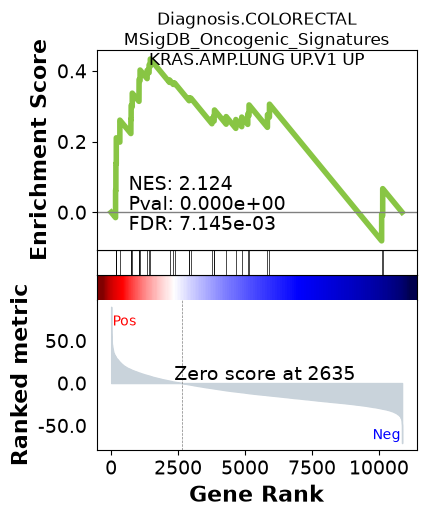

In [23]:
# preRankResultsDict.keys()
print(significantTermsDF.columns)
selectRows = significantTermsDF.loc[:, 'geneSetDB'] == 'MSigDB_Oncogenic_Signatures' 
display( significantTermsDF.loc[selectRows, :].head() )

def testPlotGSEAPrerank():
    geneSetDB = 'MSigDB_Oncogenic_Signatures' #'clade' #'KEGG_2026'
    termToGraph = 'GAVISH_3CA_MALIGNANT_METAPROGRAM_34_PLATELET_ACTIVATION' #c4 'Simple_repeat' #'PLATELET ACTIVATION'
    termToGraph = 'KRAS.AMP.LUNG UP.V1 UP' #'Simple_repeat' #'PLATELET ACTIVATION'
    
    fig = plotGSEAPrerank(
                            GSEA_CONFIG, 
                            preRankResults=preRankResultsDict[geneSetDB],
                            termToGraph=termToGraph,	
                            geneSetDB=geneSetDB
                        )
    
    title = fig._suptitle.get_text()
    outDir = f'{imgOutDir}/{geneSetDB}/{GSEA_CONFIG.diagnosis}'
    os.makedirs(outDir, exist_ok=True)
    saveFigure(fig,
               title,
               outDir,
               prefix="")
    
testPlotGSEAPrerank()

2026-11-22 10:38:46,576 WARNING 2784187955.py <module>() line:3] [AEDWIP we probably want to create dotplot that shows all diagnosis]


does c8 show tissue/organ separation?


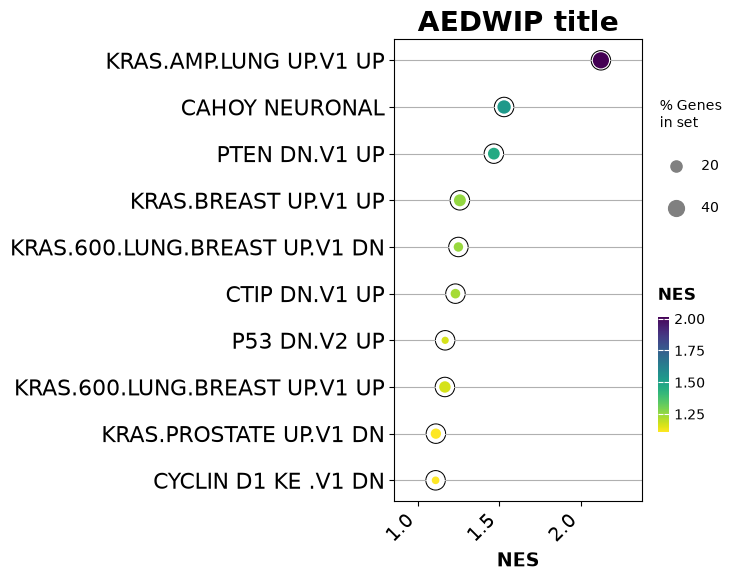

In [24]:
from gseapy import  dotplot

logger.warning(f'AEDWIP we probably want to create dotplot that shows all diagnosis')
print('does c8 show tissue/organ separation?')

# C8: Cell Type Signature Gene Sets (Organ/Tissue Validation)
# C4: 3CA (Curated Cancer Cell Atlas) (Cancer Specificity)
# C6: Oncogenic Signature Gene Sets (Mechanism Validation)

def testDotPlot():
    # geneSetDB = 'c4.all.v2026.1.Hs.symbols.gmt'
    # gseapRerank = preRankResultsDict[geneSetDB],
    gseaPrerank = preRankResultsDict['MSigDB_Oncogenic_Signatures']

    df=gseaPrerank.res2d

    panel = dotplot(
        df,
        top_term=10,
        # column name in df that map the dot colors. Default: Adjusted P-value.
        column='NES', #  #"FDR q-val",
        # X, Categorical variable in df that map the x-axis data. Default: None.
        x='Gene_set', # set x axis, so you could do a multi-sample/library comparsion
        # y Categorical variable in df that map the y-axis data. Default: Term.
        y='Term',
        show_ring=True,
        marker='o',
        size=3, # marker size area
        xticklabels_rot=45, 
        title="AEDWIP title"
    )
    
    plt.show()
    
testDotPlot()

In [25]:
preRankResultsDict.keys()

dict_keys(['MSigDB_Oncogenic_Signatures', 'Tabula_Sapiens', 'MSigDB_Hallmark_2020', 'KEGG_2026', 'GTEx_Tissues_V8_2023', 'ARCHS4_Tissues', 'clade', 'family'])

In [26]:
gseaPrerank = preRankResultsDict['MSigDB_Oncogenic_Signatures']
dir(gseaPrerank)

# df = gseaPrerank.res2d
# df.columns

resultsDict = gseaPrerank.results
preRankResultsDict['MSigDB_Oncogenic_Signatures'].res2d.head()

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,KRAS.AMP.LUNG UP.V1 UP,0.433460,2.124207,0.0,0.007145,0.002,13/31,13.47%,GATA1;TUBA8;F13A1;EGF;FCER1G;DYNC1I1;SDCCAG8;S...
1,prerank,SIRNA EIF4GI UP,-0.538154,-2.088184,0.0,0.000000,0.000,43/67,26.31%,ATP1A1;ESYT1;HSPD1;CCT4;SLC25A3;FXYD3;ALDH7A1;...
2,prerank,CAMP UP.V1 UP,-0.448160,-1.883202,0.0,0.002668,0.006,76/150,27.06%,SEC61A1;HSPA5;ATP1A1;PPIB;MAGED1;TMED9;RPN1;HD...
3,prerank,RB DN.V1 UP,-0.470089,-1.841093,0.0,0.003853,0.013,44/78,28.58%,AHCY;MYC;EI24;MAPK13;PEX11B;MCMBP;HES1;PCNA;PR...
4,prerank,BCAT BILD ET AL UP,-0.530947,-1.840691,0.0,0.002890,0.013,17/32,22.10%,SLC35C2;SCAMP4;TAGLN;AXIN2;CALR;MTCH2;ACTN4;ZN...
